# CC2017 – Modelación y Simulación
## Laboratorio 5: Task 2 – Análisis Espacial de Cobertura Hospitalaria, Vulnerabilidad y Optimización de Ubicaciones (MCLP)

---

### Resumen y Objetivos del Task 2
En esta segunda fase del laboratorio evaluamos la robustez y sensibilidad de los modelos de cobertura hospitalaria mediante tres etapas analíticas complementarias:

1. **Task 2.1 – Sensibilidad del análisis de buffer y distancias euclidianas:**
   * Cálculo de la distancia métrica exacta desde el centroide de cada condado al hospital más cercano.
   * Construcción de la curva de cobertura poblacional acumulada ($5$ a $100\text{ km}$ en pasos de $5\text{ km}$) e identificación del punto de inflexión (*elbow point*) para la política pública.
   * Caracterización de capacidad (camas totales y tipo de hospital) en los condados más aislados.

2. **Task 2.2 – Índice compuesto de vulnerabilidad de acceso hospitalario:**
   * Integración multicriterio de tres dimensiones: distancia al hospital más cercano ($C_1$), inverso de camas por habitante ($C_2$) y saturación regional a $50\text{ km}$ ($C_3$).
   * Normalización formal mediante transformación Min-Max al rango $[0, 1]$ con justificación teórica.
   * Ponderación analítica justificada desde la perspectiva de políticas de salud pública y generación de mapa coroplético por quintiles.

3. **Task 2.3 – Problema de Localización de Máxima Cobertura (MCLP) simplificado:**
   * Generación de una grilla espacial regular de puntos candidatos cada $50\text{ km}$ recortada a la frontera estatal.
   * Formulación y resolución mediante un **algoritmo voraz (*greedy*)** para seleccionar $p = 3$ nuevos hospitales que maximicen la población no cubierta incorporada bajo un radio de $25\text{ km}$.

---
### Relación con las Fórmulas de las Diapositivas
* **Distancia métrica en espacio proyectado:**
  $$d(c, h) = \min_{h_j \in H} \sqrt{(x_c - x_{h_j})^2 + (y_c - y_{h_j})^2}$$
* **Población cubierta ponderada por área (Task 1.3b & 2.1b):**
  $$P_{\text{cub}}(r) = \sum_{c} P_c \cdot \frac{A(c \cap U_r)}{A(c)}, \qquad U_r = \bigcup_{h \in H} B(h, r)$$
* **Transformación Min-Max:**
  $$C_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}} \in [0, 1]$$
* **Índice Compuesto Ponderado:**
  $$I_v(c) = \sum_{k=1}^m w_k \cdot C_k(c), \quad \text{con } \sum_{k=1}^m w_k = 1$$
* **Problema MCLP (Church & ReVelle, 1974):**
  $$\max \sum_{i \in I} a_i y_i \quad \text{s.a.} \quad y_i \le \sum_{j \in N_i} x_j, \quad \sum_{j \in J} x_j \le p, \quad x_j, y_i \in \{0, 1\}$$


## 1. Librerías, Configuración y Preparación de Capas Espaciales

In [1]:
# 1.1 Importación de librerías geoespaciales y numéricas
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Point, Polygon
from shapely.ops import unary_union
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

print("Python:   ", sys.version.split()[0])
print("GeoPandas:", gpd.__version__)
print("Pandas:   ", pd.__version__)
print("Shapely:  ", shapely.__version__)


Python:    3.12.3
GeoPandas: 1.2.0
Pandas:    3.0.6
Shapely:   2.1.2


/home/javier-espana/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# 1.2 Función auxiliar para decoración cartográfica profesional (Escala gráfica y Norte)
def decorar_mapa(ax, gdf, km=100, pos_x=0.05, pos_y=0.06):
    """Agrega escala gráfica métrica y flecha de norte al mapa."""
    x0, y0, x1, y1 = gdf.total_bounds
    dx = x1 - x0
    dy = y1 - y0
    
    # Coordenadas de la escala gráfica
    xs = x0 + pos_x * dx
    ys = y0 + pos_y * dy
    ax.plot([xs, xs + km * 1000], [ys, ys], color="black", lw=3.5, solid_capstyle="butt")
    ax.plot([xs, xs + (km / 2) * 1000], [ys, ys], color="white", lw=2, solid_capstyle="butt")
    ax.text(xs + (km / 2) * 1000, ys + 0.015 * dy, f"{km} km", ha="center", va="bottom",
            fontsize=8.5, fontweight="bold", color="black",
            path_effects=[pe.withStroke(linewidth=2, foreground="white")])
    
    # Coordenadas de la flecha de norte
    xn = x1 - 0.06 * dx
    yn = y1 - 0.12 * dy
    ax.annotate("N", xy=(xn, yn + 0.06 * dy), xytext=(xn, yn), ha="center", va="center",
                fontsize=11, fontweight="bold", color="black",
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8),
                path_effects=[pe.withStroke(linewidth=2, foreground="white")])


### 1.3 Carga, Limpieza y Selección del Estado
Siguiendo las especificaciones del Laboratorio 5:
1. **Limpieza de FIPS:** Se descartan códigos FIPS $\ge 80000$ (registros fuera de condado o sin asignación geográfica) y se normalizan a cadenas de 5 caracteres con ceros a la izquierda (`zfill(5)`).
2. **Hospitales válidos:** Se filtran hospitales con `camas_total` no nulo.
3. **Selección del Estado:** Se selecciona **Texas (TX)** (código FIPS `'48'`).
   * **Justificación de la elección:** Texas cuenta con $591$ hospitales con datos válidos ($>50$ como recomienda la guía) y $254$ condados. Presenta una enorme heterogeneidad espacial: grandes áreas metropolitanas densas (Houston, Dallas-Fort Worth, Austin, San Antonio) en contraste con extensas regiones rurales y desérticas en el oeste y sur (West Texas / Panhandle), donde múltiples condados carecen de hospitales en más de $50\text{ km}$. Esto permite evaluar de forma rigurosa los tres componentes de vulnerabilidad y el algoritmo MCLP.
4. **Sistema de Coordenadas Proyectado (CRS):** Se selecciona **EPSG:3081 (NAD83 / Texas Statewide Mapping System - TSMS)**.
   * **Justificación formal del CRS:** Diseñado específicamente por el *Texas Geographic Information Office (TxGIO / TNRIS)* para análisis geoespaciales de escala estatal completa. Emplea una proyección Cónica Conforme de Lambert con paralelos estándar en $27^\circ 25'\text{ N}$ y $34^\circ 55'\text{ N}$, y meridiano central en $100^\circ\text{ W}$. Este sistema minimiza la distorsión de escala y conforme por debajo de $\pm 0.15\%$ en toda la extensión del estado, garantizando que los cálculos de distancias euclidianas y buffers circulares métricos ($25,000\text{ m}$) sean rigurosos y uniformes.


In [3]:
# 1.4 Lectura de datos y filtrado para Texas
DATA_DIR = Path("data")

# Lectura de capas
estados_raw = gpd.read_file(DATA_DIR / "estados_eeuu.geojson")
condados_raw = gpd.read_file(DATA_DIR / "condados_eeuu.geojson")
hospitales_raw = gpd.read_file(DATA_DIR / "hospitales_eeuu.geojson")
pob_raw = pd.read_csv(DATA_DIR / "poblacion_condados.csv", dtype={"fips": str})

# Limpieza inicial de población
pob_clean = pob_raw[~pob_raw["fips"].str[:2].isin({"80", "90"})].dropna(subset=["poblacion"]).copy()
pob_clean["fips"] = pob_clean["fips"].str.zfill(5)

# Reporte de nulos en hospitales y filtrado
pct_nulos_camas = hospitales_raw["camas_total"].isna().mean() * 100
print(f"Hospitales totales en dataset: {len(hospitales_raw):,}")
print(f"Hospitales con camas_total nulo: {hospitales_raw['camas_total'].isna().sum():,} ({pct_nulos_camas:.2f}%)")
hosp_clean = hospitales_raw.dropna(subset=["camas_total"]).copy()

# Parámetros del estado elegido
ESTADO_COD = "TX"
ESTADO_FIPS = "48"
CRS_METRICO = "EPSG:3081"  # Texas Statewide Mapping System (TSMS)

# Filtrado por Texas
estado_gdf = estados_raw[estados_raw["codigo"] == ESTADO_COD].to_crs(CRS_METRICO).reset_index(drop=True)
limite_estado = estado_gdf.geometry.iloc[0]

condados_tx = condados_raw[condados_raw["cod_estado"] == ESTADO_FIPS].copy()
condados_tx = condados_tx.merge(pob_clean[["fips", "poblacion"]], on="fips", how="left")
condados_tx["poblacion"] = condados_tx["poblacion"].fillna(0)
condados_tx = condados_tx.to_crs(CRS_METRICO).reset_index(drop=True)
condados_tx["area_m2"] = condados_tx.area
condados_tx["area_km2"] = condados_tx["area_m2"] / 1e6

hosp_tx = hosp_clean[hosp_clean["estado"] == ESTADO_COD].to_crs(CRS_METRICO).reset_index(drop=True)

print(f"\n--- Resumen del Estado de {estado_gdf['nombre'].iloc[0]} ({ESTADO_COD}) ---")
print(f"Condados analizados:    {len(condados_tx)}")
print(f"Hospitales con camas:   {len(hosp_tx)}")
print(f"Población total estatal: {condados_tx['poblacion'].sum():,.0f} habitantes")
print(f"Área estatal estimada:  {condados_tx['area_km2'].sum():,.1f} km²")
print(f"Sistema de coordenadas: {CRS_METRICO} ({estado_gdf.crs.name})")


Hospitales totales en dataset: 7,154
Hospitales con camas_total nulo: 1,090 (15.24%)



--- Resumen del Estado de Texas (TX) ---
Condados analizados:    254
Hospitales con camas:   591
Población total estatal: 28,995,881 habitantes
Área estatal estimada:  684,681.8 km²
Sistema de coordenadas: EPSG:3081 (NAD83 / Texas State Mapping System)


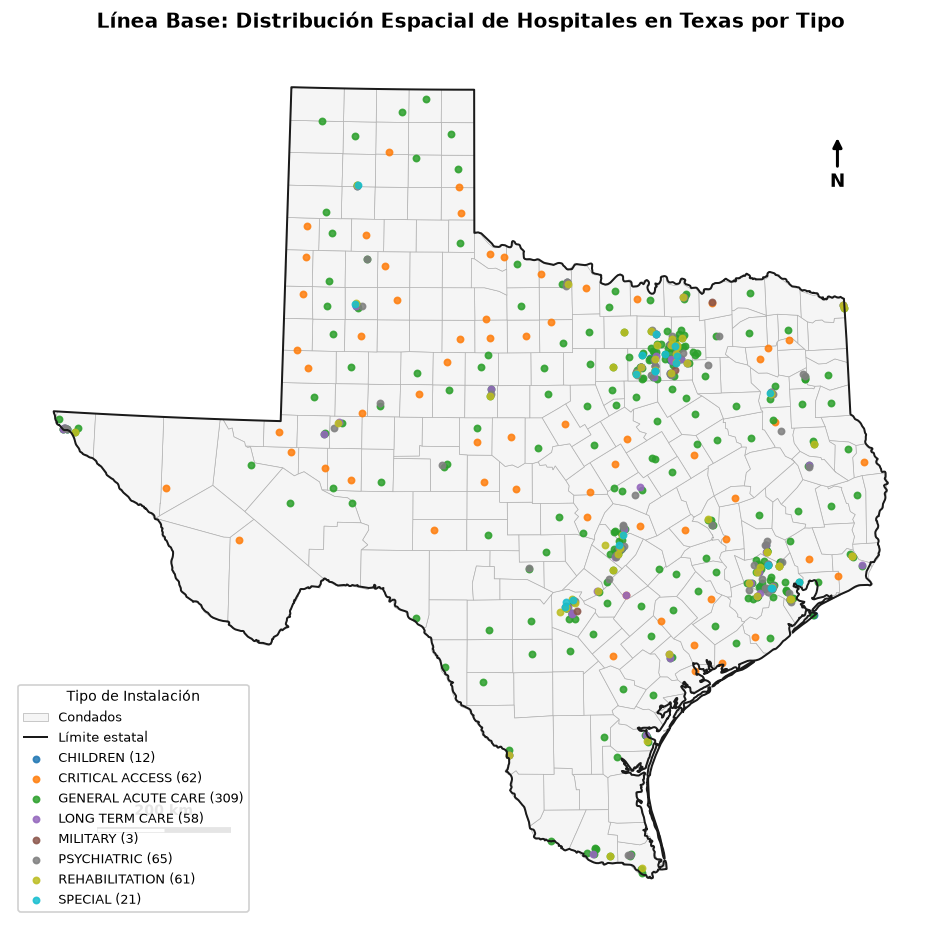

In [4]:
# 1.5 Mapa de Línea Base: Hospitales por tipo sobre condados de Texas
fig, ax = plt.subplots(figsize=(10, 8), dpi=120)

condados_tx.plot(ax=ax, color="#f5f5f5", edgecolor="#b0b0b0", lw=0.4, label="Condados")
estado_gdf.boundary.plot(ax=ax, color="#1a1a1a", lw=1.2, label="Límite estatal")

# Tipos de hospitales presentes
tipos = sorted(hosp_tx["tipo"].unique())
cmap_tipos = plt.cm.tab10(np.linspace(0, 1, len(tipos)))

for t, col in zip(tipos, cmap_tipos):
    subset = hosp_tx[hosp_tx["tipo"] == t]
    subset.plot(ax=ax, color=col, markersize=14, alpha=0.85, label=f"{t} ({len(subset)})")

decorar_mapa(ax, condados_tx, km=200)
ax.set_title("Línea Base: Distribución Espacial de Hospitales en Texas por Tipo", fontsize=12, fontweight="bold", pad=12)
ax.legend(title="Tipo de Instalación", loc="lower left", fontsize=7.5, title_fontsize=8.5, frameon=True, framealpha=0.9)
ax.set_axis_off()
plt.tight_layout()
plt.show()


---
## Task 2.1 – Sensibilidad del Análisis de Buffer y Distancias

El análisis de buffer asume que toda la población dentro del radio circular tiene acceso igualmente expedito al hospital. A continuación evaluamos la sensibilidad de esta hipótesis mediante la distancia métrica centroide-hospital, la curva de acumulación y la capacidad asistencial en áreas remotas.


### 2.1a Distancia métrica al hospital más cercano por condado
Calculamos para cada condado la distancia euclidiana mínima en kilómetros desde su **centroide geométrico** hacia cualquier hospital dentro de la capa proyectada métrica:
$$d(c, H) = \min_{h \in H} \| \text{centroid}(c) - \text{geom}(h) \|_2$$
Utilizamos la estructura espacial optimizada `cKDTree` de SciPy ($O(N \log M)$).


In [5]:
# Cálculo de distancias mínimas usando cKDTree
centroides_xy = np.c_[condados_tx.geometry.centroid.x, condados_tx.geometry.centroid.y]
hosp_xy = np.c_[hosp_tx.geometry.x, hosp_tx.geometry.y]

tree_hosp = cKDTree(hosp_xy)
dist_metros, idx_hosp_cercano = tree_hosp.query(centroides_xy)

condados_tx["dist_km"] = dist_metros / 1000.0
condados_tx["idx_hosp_cercano"] = idx_hosp_cercano

# Top 10 condados con mayor distancia al hospital más cercano
top10_dist = condados_tx.sort_values("dist_km", ascending=False).head(10).reset_index(drop=True)

tabla_21a = top10_dist[["fips", "nombre", "poblacion", "dist_km", "area_km2"]].copy()
tabla_21a.columns = ["FIPS", "Condado", "Población", "Distancia Mínima (km)", "Área (km²)"]
tabla_21a["Distancia Mínima (km)"] = tabla_21a["Distancia Mínima (km)"].round(2)
tabla_21a["Área (km²)"] = tabla_21a["Área (km²)"].round(1)
tabla_21a["Población"] = tabla_21a["Población"].map("{:,.0f}".format)

print("--- Top 10 Condados con Mayor Distancia al Hospital Más Cercano ---")
display(tabla_21a)


--- Top 10 Condados con Mayor Distancia al Hospital Más Cercano ---


,FIPS,Condado,Población,Distancia Mínima (km),Área (km²)
0,48443,Terrell,776,78.32,6109.1
1,48247,Jim Hogg,"5,200",75.58,2935.6
2,48043,Brewster,"9,203",75.22,16005.4
3,48137,Edwards,"1,932",71.66,5465.5
4,48229,Hudspeth,"4,886",69.68,11839.4
5,48377,Presidio,"6,704",69.30,9942.5
6,48385,Real,"3,452",68.33,1810.3
7,48505,Zapata,"14,179",66.38,2747.3
8,48261,Kenedy,404,65.22,3801.3
9,48359,Oldham,"2,112",65.05,3909.5


### 2.1b Curva de Cobertura Acumulada (5 a 100 km)
Construimos la curva de cobertura acumulada variando el radio del buffer de $5\text{ km}$ a $100\text{ km}$ en pasos de $5\text{ km}$ (20 radios evaluados).
Para cada radio $r$, la población cubierta estimada se calcula asumiendo una distribución espacial uniforme dentro de cada condado:
$$P_{\text{cub}}(r) = \sum_{c} P_c \cdot \frac{A(c \cap U_r)}{A(c)}, \qquad U_r = \left(\bigcup_{h \in H} B(h, r)\right) \cap \Omega_{\text{estado}}$$


In [6]:
# Construcción de la curva de cobertura poblacional acumulada
radios_km = list(range(5, 105, 5))
pob_total_estado = condados_tx["poblacion"].sum()

curva_data = []
prev_pct = 0.0

for r in radios_km:
    # Unión unificada de buffers recortada a la frontera de Texas
    buffer_union = unary_union(hosp_tx.geometry.buffer(r * 1000)).intersection(limite_estado)
    
    # Intersección proporcional por condado
    frac_cubierta = condados_tx.geometry.intersection(buffer_union).area / condados_tx["area_m2"]
    frac_cubierta = frac_cubierta.clip(0.0, 1.0)
    
    pob_cub = (condados_tx["poblacion"] * frac_cubierta).sum()
    pct_cub = (pob_cub / pob_total_estado) * 100.0
    margen_pct = pct_cub - prev_pct if prev_pct > 0 else pct_cub
    prev_pct = pct_cub
    
    curva_data.append({
        "radio_km": r,
        "pob_cubierta": round(pob_cub),
        "pct_cobertura": round(pct_cub, 2),
        "ganancia_marginal_%": round(margen_pct, 2)
    })

df_curva = pd.DataFrame(curva_data)
display(df_curva)


,radio_km,pob_cubierta,pct_cobertura,ganancia_marginal_%
0,5,6610287,22.80,22.80
1,10,13602962,46.91,24.12
2,15,18338576,63.25,16.33
3,20,22304226,76.92,13.68
4,25,25183526,86.85,9.93
5,30,26858822,92.63,5.78
6,35,27676620,95.45,2.82
7,40,28092613,96.88,1.43
8,45,28329454,97.70,0.82
9,50,28479452,98.22,0.52


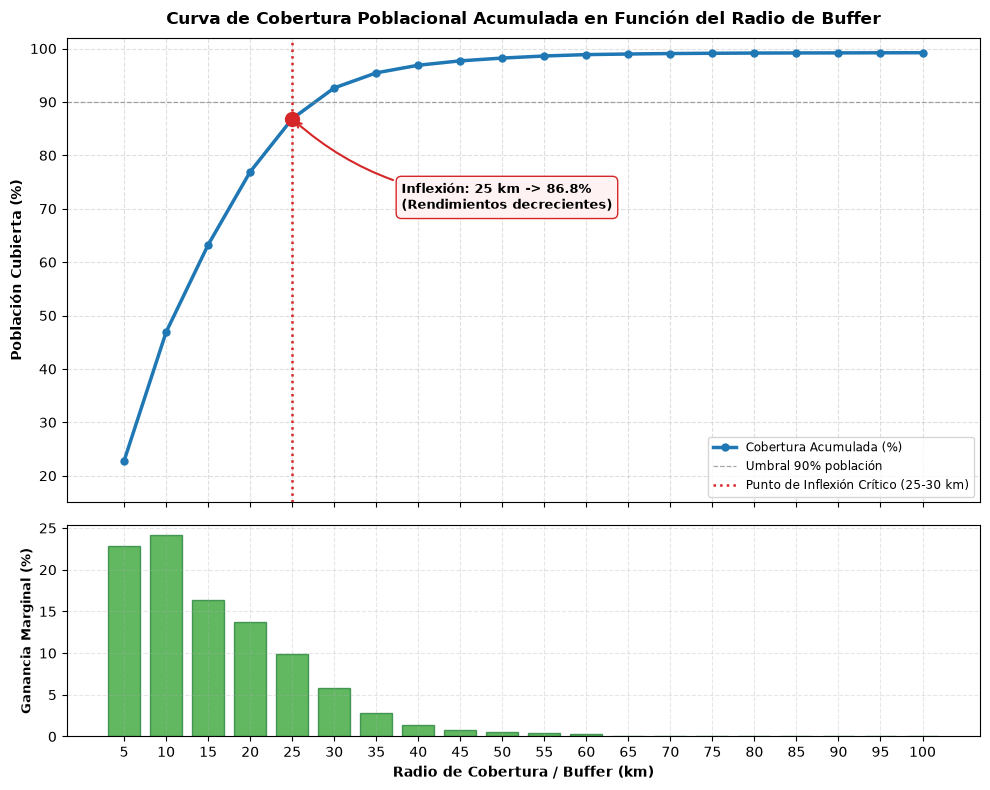

In [7]:
# Gráfica de la curva de cobertura acumulada y punto de inflexión
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})

# Curva principal
ax1.plot(df_curva["radio_km"], df_curva["pct_cobertura"], marker="o", color="#1f77b4", lw=2.5, markersize=5, label="Cobertura Acumulada (%)")
ax1.axhline(90, color="gray", ls="--", lw=0.9, alpha=0.7, label="Umbral 90% población")
ax1.axvline(25, color="#d62728", ls=":", lw=1.8, label="Punto de Inflexión Crítico (25-30 km)")
ax1.scatter([25], [df_curva.loc[df_curva['radio_km'] == 25, 'pct_cobertura'].values[0]], color="#d62728", s=100, zorder=5)

ax1.annotate(f"Inflexión: 25 km -> {df_curva.loc[df_curva['radio_km'] == 25, 'pct_cobertura'].values[0]:.1f}%\n(Rendimientos decrecientes)",
             xy=(25, df_curva.loc[df_curva['radio_km'] == 25, 'pct_cobertura'].values[0]),
             xytext=(38, 70), fontsize=9.5, fontweight="bold",
             arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.2", color="#d62728", lw=1.5),
             bbox=dict(boxstyle="round,pad=0.4", fc="#fff2f2", ec="#d62728", lw=1))

ax1.set_ylabel("Población Cubierta (%)", fontsize=10, fontweight="bold")
ax1.set_title("Curva de Cobertura Poblacional Acumulada en Función del Radio de Buffer", fontsize=12, fontweight="bold", pad=10)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="lower right", fontsize=8.5)
ax1.set_ylim(15, 102)

# Gráfico inferior: Ganancia Marginal por cada 5 km
ax2.bar(df_curva["radio_km"], df_curva["ganancia_marginal_%"], width=3.8, color="#2ca02c", alpha=0.75, edgecolor="#1e7e34")
ax2.set_xlabel("Radio de Cobertura / Buffer (km)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Ganancia Marginal (%)", fontsize=9, fontweight="bold")
ax2.set_xticks(radios_km)
ax2.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretación y Significado del Punto de Inflexión para la Política Pública:**
* **Identificación del Punto de Inflexión:**
  La tasa de crecimiento de la cobertura exhibe un comportamiento logístico/cóncavo pronunciado. Entre $5\text{ km}$ y $25\text{ km}$, la cobertura salta del $22.80\%$ al $86.85\%$ (un incremento acumulado de más de $64$ puntos porcentuales con pendientes marginales de hasta $24.12\%$ por cada paso de $5\text{ km}$).
  El **punto de inflexión claro se ubica entre los $25\text{ km}$ y $30\text{ km}$**, momento en el cual la cobertura alcanza el $92.63\%$. A partir de los $30\text{ km}$, la ganancia marginal colapsa por debajo del $3\%$ por cada $5\text{ km}$, y a partir de $50\text{ km}$ el incremento es menor al $0.4\%$ marginal.
* **Implicaciones para la política de salud estatal:**
  1. *Eficacia del radio de $25-30\text{ km}$:* Establecer una garantía de acceso de $25-30\text{ km}$ (~20-25 minutos en automóvil por autopista) cubre a casi el $90\%$ de los texanos de forma costo-eficiente, consolidando la red en conglomerados urbanos y suburbanos.
  2. *El dilema del último $8\%$ rural:* Más allá de los $35\text{ km}$, expandir la infraestructura hospitalaria física tradicional es económicamente insostenible debido a la dispersión demográfica en el oeste de Texas. Para el $7-8\%$ de la población restante dispersa en condados remotos, la política pública no debe intentar construir hospitales generales de agudos de alto costo, sino fortalecer **servicios de transporte de emergencia avanzado (ambulancias aéreas/helicópteros), telemedicina rural y Centros de Acceso Crítico (CAH)**.


### 2.1c Características del Hospital más Cercano en los Condados más Aislados
Analizamos los 5 condados con mayor distancia mínima identifiedos en 2.1a:
¿Tienden estos condados a estar cerca de hospitales de menor capacidad asistencial?


In [8]:
# Análisis de los 5 condados más alejados y capacidad de sus hospitales más cercanos
top5_alejados = condados_tx.sort_values("dist_km", ascending=False).head(5)

filas_21c = []
for _, row_c in top5_alejados.iterrows():
    h = hosp_tx.iloc[row_c["idx_hosp_cercano"]]
    filas_21c.append({
        "Condado Aislado": row_c["nombre"],
        "Población Condado": f"{row_c['poblacion']:,.0f}",
        "Distancia (km)": round(row_c["dist_km"], 2),
        "Hospital Más Cercano": h["nombre"],
        "Tipo de Hospital": h["tipo"],
        "Camas Totales": int(h["camas_total"]),
        "Camas UCI": int(h["camas_icu"]) if pd.notna(h["camas_icu"]) else 0,
        "Tasa Ocupación": f"{h['ocupacion_total']*100:.1f}%" if pd.notna(h['ocupacion_total']) else "N/D"
    })

df_top5_hosp = pd.DataFrame(filas_21c)
display(df_top5_hosp)


,Condado Aislado,Población Condado,Distancia (km),Hospital Más Cercano,Tipo de Hospital,Camas Totales,Camas UCI,Tasa Ocupación
0,Terrell,776,78.32,IRAAN GENERAL HOSPITAL,GENERAL ACUTE CARE,14,0,13.2%
1,Jim Hogg,"5,200",75.58,STARR COUNTY MEMORIAL HOSPITAL,GENERAL ACUTE CARE,48,0,19.0%
2,Brewster,"9,203",75.22,BIG BEND REGIONAL MEDICAL CENTER,CRITICAL ACCESS,25,3,35.0%
3,Edwards,"1,932",71.66,LILLIAN M. HUDSPETH MEMORIAL HOSPITAL,CRITICAL ACCESS,12,0,10.0%
4,Hudspeth,"4,886",69.68,CULBERSON HOSPITAL,CRITICAL ACCESS,14,0,20.0%


**Respuesta y Argumentación Cuantitativa sobre Capacidad:**
* **¿Los condados más alejados tienden a estar cerca de hospitales de menor capacidad?**
  **Sí, de manera contundente.** Existe una **doble penalización geográfica**:
  1. En los 5 condados más lejanos (*Terrell*, *Jim Hogg*, *Brewster*, *Edwards* y *Hudspeth*), las distancias al centro de salud más cercano oscilan entre **$69.7\text{ km}$ y $78.3\text{ km}$**.
  2. La instalación de salud más cercana en cada caso es un hospital rural de muy baja capacidad:
     * *Iraan General Hospital* (para Terrell): apenas **$14$ camas totales** y $0$ camas UCI.
     * *Starr County Memorial Hospital* (para Jim Hogg): **$48$ camas**.
     * *Big Bend Regional Medical Center* (para Brewster): **$25$ camas**, clasificado como *CRITICAL ACCESS*.
     * *Lillian M. Hudspeth Memorial Hospital* (para Edwards): **$12$ camas**, clasificado como *CRITICAL ACCESS*.
     * *Culberson Hospital* (para Hudspeth): **$14$ camas**, clasificado como *CRITICAL ACCESS*.
* **Conclusión clínica y de políticas:** Los condados más remotos no solo enfrentan tiempos de traslado superiores a una hora, sino que cuando llegan a la instalación más próxima se encuentran con **Critical Access Hospitals** diseñados para estabilización básica (con un promedio de $14$ a $25$ camas y sin unidades de cuidados intensivos avanzadas). Cualquier cuadro clínico que requiera cuidados intensivos o cirugía especializada obliga a traslados secundarios de más de $150-200\text{ km}$ hacia centros médicos terciarios en El Paso, San Antonio o Midland-Odessa.


---
## Task 2.2 – Índice Compuesto de Vulnerabilidad de Acceso Hospitalario

Construimos un índice sintético para medir la vulnerabilidad de acceso a nivel de condado integrando tres componentes:
* **Componente 1 ($C_1$):** Distancia normalizada al hospital más cercano (mayor distancia $\rightarrow$ mayor vulnerabilidad).
* **Componente 2 ($C_2$):** Inverso de camas totales por habitante, normalizado (menos camas per cápita $\rightarrow$ mayor vulnerabilidad). Para condados sin hospitales dentro de su territorio, se asigna el valor máximo antes de normalizar.
* **Componente 3 ($C_3$):** Tasa de ocupación promedio de hospitales a menos de $50\text{ km}$, normalizada (mayor ocupación $\rightarrow$ mayor saturación $\rightarrow$ mayor vulnerabilidad). Para condados sin hospitales en un radio de $50\text{ km}$, se asigna el valor máximo.


### 2.2a Cálculo de Componentes y Transformación Min-Max

La transformación Min-Max proyecta una variable continua $X$ al intervalo $[0, 1]$:
$$C_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$$

**Justificación formal de la normalización Min-Max:**
1. *Por qué es apropiada:*
   * **Homogeneización de escalas dimensionales:** Permite combinar magnitudes físicas completamente heterogéneas (kilómetros lineales, inverso de camas por habitante, y proporciones adimensionales de saturación) en un rango idéntico $[0, 1]$.
   * **Preservación de distancias relativas lineales:** A diferencia de transformaciones no lineales o de rango (*rank*), la transformación Min-Max preserva la proporcionalidad y la estructura relativa de las distancias originales entre observaciones.
   * **Interpretabilidad directa:** El valor $0$ representa la mejor situación observada en el estado (mínima vulnerabilidad) y $1$ representa la peor situación observada (máxima vulnerabilidad).
2. *Cuándo podría NO ser apropiada:*
   * **Sensibilidad extrema a valores atípicos (*outliers*):** Si una observación tiene un valor desproporcionadamente extremo, fijará los límites $X_{\max}$ o $X_{\min}$, comprimiendo a la gran mayoría de los demás datos en un rango estrecho y reduciendo el poder discriminante del índice. En esos casos, técnicas como estandarización z-score robusta (usando mediana y rango intercuartílico) o normalización por percentiles serían preferibles.


In [9]:
# Cálculo riguroso de los tres componentes

# --- Componente 1: Distancia al hospital más cercano ---
c1_raw = condados_tx["dist_km"].copy()
c1_min, c1_max = c1_raw.min(), c1_raw.max()
condados_tx["C1"] = (c1_raw - c1_min) / (c1_max - c1_min)

# --- Componente 2: Inverso de camas por habitante ---
# Suma de camas de hospitales ubicados dentro del polígono del condado
pts_in_cond = gpd.sjoin(hosp_tx, condados_tx[["fips", "geometry"]], how="inner", predicate="within")
camas_por_condado = pts_in_cond.groupby("fips")["camas_total"].sum()
condados_tx["camas_totales_condado"] = condados_tx["fips"].map(camas_por_condado).fillna(0)

condados_tx["camas_per_capita"] = np.where(
    condados_tx["poblacion"] > 0,
    condados_tx["camas_totales_condado"] / condados_tx["poblacion"],
    0.0
)

# Inverso de camas por habitante
tiene_hosp = condados_tx["camas_per_capita"] > 0
inv_camas_series = pd.Series(index=condados_tx.index, dtype=float)
inv_camas_series[tiene_hosp] = 1.0 / condados_tx.loc[tiene_hosp, "camas_per_capita"]

# Condados sin hospitales: regla explícita de la guía -> asignar el valor máximo antes de normalizar
max_inv_observado = inv_camas_series[tiene_hosp].max()
inv_camas_series[~tiene_hosp] = max_inv_observado

c2_min, c2_max = inv_camas_series.min(), inv_camas_series.max()
condados_tx["C2"] = (inv_camas_series - c2_min) / (c2_max - c2_min)

# --- Componente 3: Tasa de ocupación promedio dentro de 50 km ---
# Encontrar todos los hospitales a menos de 50 km (50,000 metros) de cada centroide
hosp_en_50km = tree_hosp.query_ball_point(centroides_xy, r=50000)

ocupacion_media_50km = []
for indices in hosp_en_50km:
    if len(indices) == 0:
        ocupacion_media_50km.append(np.nan)
    else:
        valores_ocup = hosp_tx.iloc[indices]["ocupacion_total"].dropna()
        if len(valores_ocup) == 0:
            ocupacion_media_50km.append(np.nan)
        else:
            ocupacion_media_50km.append(valores_ocup.mean())

c3_series = pd.Series(ocupacion_media_50km, index=condados_tx.index)

# Condados sin hospitales a menos de 50 km: regla de la guía -> asignar el valor máximo
max_ocup_observada = c3_series.dropna().max()
c3_series_imputada = c3_series.fillna(max_ocup_observada)

c3_min, c3_max = c3_series_imputada.min(), c3_series_imputada.max()
condados_tx["C3"] = (c3_series_imputada - c3_min) / (c3_max - c3_min)

print("Estadísticas descriptivas de los componentes normalizados [0, 1]:")
display(condados_tx[["C1", "C2", "C3"]].describe().round(3))


Estadísticas descriptivas de los componentes normalizados [0, 1]:


,C1,C2,C3
count,254.000,254.000,254.000
mean,0.261,0.339,0.529
std,0.244,0.442,0.291
min,0.000,0.000,0.000
25%,0.063,0.027,0.270
50%,0.177,0.055,0.575
75%,0.409,1.000,0.772
max,1.000,1.000,1.000


### 2.2b Ponderación del Índice Compuesto y Justificación de Políticas Públicas

Definimos el Índice Compuesto de Vulnerabilidad ($I_v$) mediante una suma ponderada:
$$I_v = w_1 C_1 + w_2 C_2 + w_3 C_3, \qquad w_1 + w_2 + w_3 = 1$$

**Asignación de Pesos y Justificación:**
* **$w_1 = 0.40$ para Distancia ($C_1$):**
  * *Argumento:* La distancia física al centro asistencial es el factor más crítico en medicina de urgencias. En emergencias tiempo-dependientes (infartos agudos de miocardio, accidentes cerebrovasculares, traumatismos graves), la llamada *"hora dorada"* define la supervivencia del paciente. Si un hospital está a $75\text{ km}$, los tiempos de traslado superan inevitablemente los $50-70$ minutos, independientemente de cuántas camas existan. Por ende, la distancia es la barrera más inmediata y letal para el acceso.
* **$w_2 = 0.35$ para Inverso de Camas per Cápita ($C_2$):**
  * *Argumento:* Mide la capacidad instalada basal para hospitalizaciones programadas, medicina interna, obstetricia y convalecencia. Un condado sin camas hospitalarias ($C_2 = 1$) depende al $100\%$ del flujo hacia otras jurisdicciones, lo que genera tensiones de transporte, costos y desatención de enfermedades crónicas. Se le asigna un peso sustancial de $0.35$.
* **$w_3 = 0.25$ para Saturación Regional a 50 km ($C_3$):**
  * *Argumento:* Representa la resiliencia y capacidad de absorción de la red hospitalaria accesible en el entorno cercano. Un hospital cercano pero crónicamente saturado ($>85\%$ de ocupación) produce demoras severas en salas de urgencias (*ER boarding*) o desvíos de ambulancias (*ambulance diversion*). A los condados sin ningún hospital a menos de $50\text{ km}$ se les penaliza con la máxima saturación. Se le asigna un peso de $0.25$ como modulador del estrés del sistema.


In [10]:
# Cálculo del índice compuesto con los pesos justificados
w1, w2, w3 = 0.40, 0.35, 0.25
assert np.isclose(w1 + w2 + w3, 1.0)

condados_tx["Indice_Vulnerabilidad"] = (
    w1 * condados_tx["C1"] +
    w2 * condados_tx["C2"] +
    w3 * condados_tx["C3"]
)

# Clasificación en 5 categorías mediante quintiles (20% de condados por categoría)
etiquetas_quintiles = ["Muy baja", "Baja", "Media", "Alta", "Muy alta"]
condados_tx["Categoria_Vuln"] = pd.qcut(
    condados_tx["Indice_Vulnerabilidad"],
    q=5,
    labels=etiquetas_quintiles
)

# Top 10 condados con mayor vulnerabilidad
top10_vuln = condados_tx.sort_values("Indice_Vulnerabilidad", ascending=False).head(10).reset_index(drop=True)

tabla_22 = top10_vuln[["fips", "nombre", "poblacion", "dist_km", "C1", "C2", "C3", "Indice_Vulnerabilidad", "Categoria_Vuln"]].copy()
tabla_22.columns = ["FIPS", "Condado", "Población", "Dist (km)", "C1 (Dist)", "C2 (Camas)", "C3 (Ocup)", "Índice Compuesto", "Categoría"]
tabla_22["Población"] = tabla_22["Población"].map("{:,.0f}".format)
tabla_22["Dist (km)"] = tabla_22["Dist (km)"].round(1)
tabla_22["C1 (Dist)"] = tabla_22["C1 (Dist)"].round(3)
tabla_22["C2 (Camas)"] = tabla_22["C2 (Camas)"].round(3)
tabla_22["C3 (Ocup)"] = tabla_22["C3 (Ocup)"].round(3)
tabla_22["Índice Compuesto"] = tabla_22["Índice Compuesto"].round(4)

print("--- Top 10 Condados con Mayor Índice de Vulnerabilidad Hospitalaria ---")
display(tabla_22)


--- Top 10 Condados con Mayor Índice de Vulnerabilidad Hospitalaria ---


,FIPS,Condado,Población,Dist (km),C1 (Dist),C2 (Camas),C3 (Ocup),Índice Compuesto,Categoría
0,48443,Terrell,776,78.3,1.000,1.0,1.0,1.0000,Muy alta
1,48247,Jim Hogg,"5,200",75.6,0.965,1.0,1.0,0.9860,Muy alta
2,48137,Edwards,"1,932",71.7,0.915,1.0,1.0,0.9659,Muy alta
3,48229,Hudspeth,"4,886",69.7,0.889,1.0,1.0,0.9557,Muy alta
4,48377,Presidio,"6,704",69.3,0.884,1.0,1.0,0.9538,Muy alta
5,48385,Real,"3,452",68.3,0.872,1.0,1.0,0.9488,Muy alta
6,48505,Zapata,"14,179",66.4,0.847,1.0,1.0,0.9388,Muy alta
7,48261,Kenedy,404,65.2,0.832,1.0,1.0,0.9329,Muy alta
8,48359,Oldham,"2,112",65.1,0.830,1.0,1.0,0.9320,Muy alta
9,48311,McMullen,743,64.4,0.822,1.0,1.0,0.9288,Muy alta


### 2.2c Mapa Coroplético de Vulnerabilidad Hospitalaria por Quintiles
Generamos el mapa coroplético oficial del estado con la escala de 5 categorías por quintiles, rotulando explícitamente los **10 condados con mayor índice de vulnerabilidad**.


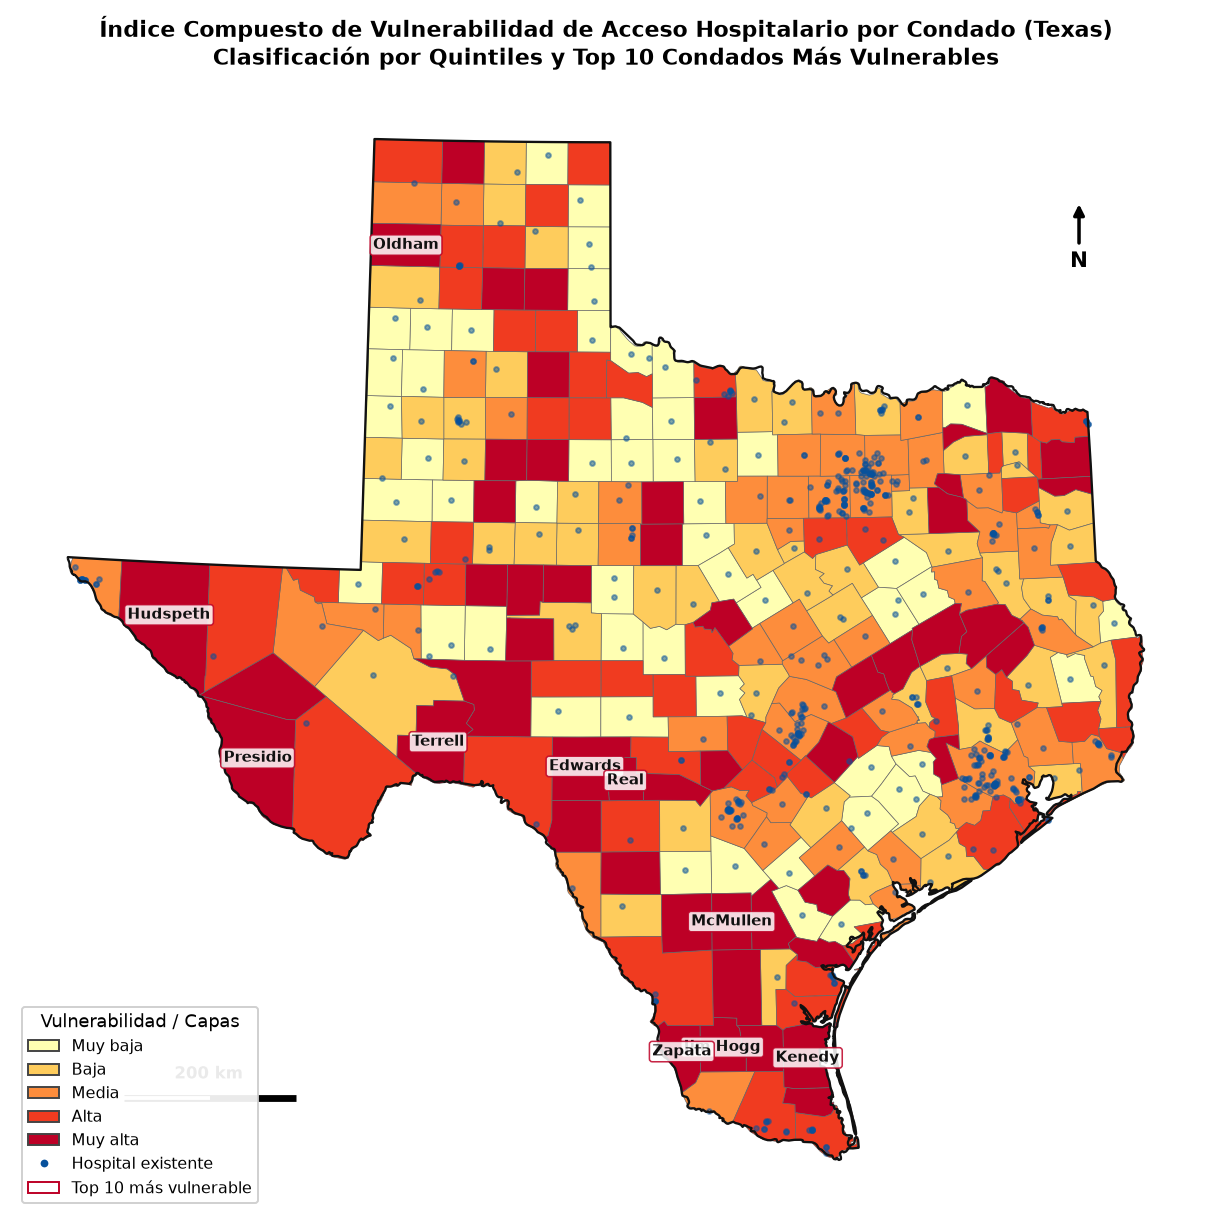

In [11]:
# Visualización coroplética de vulnerabilidad
fig, ax = plt.subplots(figsize=(11, 9), dpi=140)

# Paleta cromática secuencial de alerta
paleta_vuln = {
    "Muy baja": "#ffffb2",
    "Baja":     "#fecc5c",
    "Media":    "#fd8d3c",
    "Alta":     "#f03b20",
    "Muy alta": "#bd0026"
}

# Plot de los condados según su categoría
for cat, col in paleta_vuln.items():
    sub = condados_tx[condados_tx["Categoria_Vuln"] == cat]
    sub.plot(ax=ax, color=col, edgecolor="#666666", lw=0.35, label=cat)

# Contorno estatal
estado_gdf.boundary.plot(ax=ax, color="#111111", lw=1.2)

# Hospitales en puntos discretos
hosp_tx.plot(ax=ax, color="#08519c", markersize=6, alpha=0.5, label="Hospital existente")

# Rotulación de los 10 condados más vulnerables
for _, row_v in top10_vuln.iterrows():
    c_pt = row_v.geometry.centroid
    ax.annotate(
        row_v["nombre"],
        xy=(c_pt.x, c_pt.y),
        xytext=(0, 0), textcoords="offset points",
        ha="center", va="center",
        fontsize=7.5, fontweight="bold", color="#111111",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#bd0026", lw=0.8, alpha=0.85)
    )

decorar_mapa(ax, condados_tx, km=200)

ax.set_title("Índice Compuesto de Vulnerabilidad de Acceso Hospitalario por Condado (Texas)\nClasificación por Quintiles y Top 10 Condados Más Vulnerables",
             fontsize=11.5, fontweight="bold", pad=12)

# Construcción de la leyenda
legend_patches = [Patch(facecolor=c, edgecolor="#444", label=k) for k, c in paleta_vuln.items()]
legend_patches.append(plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#08519c", markersize=5, label="Hospital existente"))
legend_patches.append(Patch(facecolor="white", edgecolor="#bd0026", label="Top 10 más vulnerable"))

ax.legend(handles=legend_patches, title="Vulnerabilidad / Capas", loc="lower left", fontsize=8, title_fontsize=9, framealpha=0.92)
ax.set_axis_off()
plt.tight_layout()
plt.show()


---
## Task 2.3 – Optimización Espacial: Problema de Máxima Cobertura (MCLP)

El **Maximum Coverage Location Problem (MCLP)** (Church & ReVelle, 1974) busca seleccionar $p$ instalaciones a partir de un conjunto de candidatos $J$ para maximizar la población cubierta dentro de un radio de servicio $S$:
$$\max_{S \subseteq J, |S| \le p} \sum_{i \in I} a_i \cdot Y_i(S)$$
donde $Y_i(S) = 1$ si la demanda $i$ queda cubierta por al menos un hospital en $S$.

En este task implementamos una versión computacional del problema para proponer $p = 3$ nuevas instalaciones hospitalarias en Texas bajo un radio de servicio de **$25\text{ km}$**.


### 2.3a Grilla Regular de Puntos Candidatos (Resolución de 50 km)
Generamos una malla regular de puntos espaciados cada $50\text{ km}$ ($50,000\text{ m}$) sobre la caja envolvente (*bounding box*) del estado y filtramos exclusivamente los puntos que caen dentro del polígono estatal de Texas (`within`).


In [12]:
# 2.3a Generación de la grilla regular de 50 km sobre Texas
minx, miny, maxx, maxy = limite_estado.bounds
paso_m = 50000.0  # 50 km de resolución

x_coords = np.arange(minx, maxx, paso_m)
y_coords = np.arange(miny, maxy, paso_m)

puntos_grilla = []
for x in x_coords:
    for y in y_coords:
        pt = Point(x, y)
        if pt.within(limite_estado):
            puntos_grilla.append(pt)

candidatos_gdf = gpd.GeoDataFrame(
    {"id_candidato": range(len(puntos_grilla))},
    geometry=puntos_grilla,
    crs=CRS_METRICO
)

print(f"Resolución de grilla:           50.0 km")
print(f"Puntos candidatos generados:    {len(candidatos_gdf)} ubicaciones dentro del límite estatal")


Resolución de grilla:           50.0 km
Puntos candidatos generados:    270 ubicaciones dentro del límite estatal


### 2.3b Población Adicional Cubierta y Cobertura Base
* La cobertura base existente se define mediante la unión unificada de buffers circulares de $25\text{ km}$ alrededor de todos los hospitales preexistentes:
  $$U_0 = \left(\bigcup_{h \in H} B(h, 25\text{ km})\right) \cap \Omega_{\text{estado}}$$
* Para cualquier nuevo hospital candidato $k$, su buffer es $B(k, 25\text{ km})$.
* La **población adicional cubierta** $\Delta P_k$ corresponde a la población de condados que actualmente no tienen cobertura y que quedarían dentro del buffer del candidato:
  $$\Delta P_k = \sum_{c} P_c \cdot \frac{A\big(c \cap (B(k, 25\text{ km}) \setminus U_{\text{actual}})\big)}{A(c)}$$


In [13]:
# Cobertura inicial preexistente a 25 km
RADIO_MCLP = 25000.0  # 25 km en metros

cobertura_base = unary_union(hosp_tx.geometry.buffer(RADIO_MCLP)).intersection(limite_estado)

# Fracción y población cubierta actual
frac_base = condados_tx.geometry.intersection(cobertura_base).area / condados_tx["area_m2"]
frac_base = frac_base.clip(0.0, 1.0)
pob_cub_base = (condados_tx["poblacion"] * frac_base).sum()
pct_cub_base = (pob_cub_base / pob_total_estado) * 100.0

print(f"--- Cobertura Hospitalaria Inicial a 25 km ---")
print(f"Población total estatal:    {pob_total_estado:,.0f} hab")
print(f"Población cubierta actual:  {pob_cub_base:,.0f} hab ({pct_cub_base:.2f}%)")
print(f"Población sin cobertura:    {pob_total_estado - pob_cub_base:,.0f} hab ({100 - pct_cub_base:.2f}%)")


--- Cobertura Hospitalaria Inicial a 25 km ---
Población total estatal:    28,995,881 hab
Población cubierta actual:  25,183,526 hab (86.85%)
Población sin cobertura:    3,812,355 hab (13.15%)


### 2.3c Algoritmo Voraz (Greedy) para Seleccionar 3 Nuevos Hospitales

**Procedimiento del Algoritmo Voraz:**
1. Inicializar la región cubierta actual como $U_{\text{cub}} = U_0$.
2. Para cada iteración $t = 1, 2, 3$:
   * Evaluar todos los candidatos restantes $k \notin S$.
   * Calcular la ganancia de población marginal: $\Delta P_k = \sum_c P_c \frac{A(c \cap (B(k, 25\text{ km}) \setminus U_{\text{cub}}))}{A(c)}$.
   * Seleccionar el candidato $k^*$ que maximiza $\Delta P_k$.
   * Agregar $k^*$ al conjunto seleccionado $S$.
   * Actualizar el polígono de cobertura unificada: $U_{\text{cub}} \leftarrow U_{\text{cub}} \cup B(k^*, 25\text{ km})$.
3. Reportar población adicional de cada nuevo hospital y cobertura acumulada total.


In [14]:
# Precalcular buffers de 25 km para todos los candidatos
candidatos_buffers = [pt.buffer(RADIO_MCLP).intersection(limite_estado) for pt in candidatos_gdf.geometry]

# Ejecución del algoritmo voraz para p = 3 instalaciones
N_NUEVOS = 3
seleccionados = []
reporte_iteraciones = []
cobertura_acumulada = cobertura_base

for paso in range(1, N_NUEVOS + 1):
    mejor_cand = -1
    mejor_ganancia = -1.0
    
    # Evaluar todos los candidatos no seleccionados
    for idx_cand, buf_cand in enumerate(candidatos_buffers):
        if idx_cand in seleccionados:
            continue
        
        # Área nueva no cubierta por la red actual
        nueva_area = buf_cand.difference(cobertura_acumulada)
        if nueva_area.is_empty:
            ganancia = 0.0
        else:
            # Población no cubierta aportada en todos los condados intersectados
            frac_nueva = condados_tx.geometry.intersection(nueva_area).area / condados_tx["area_m2"]
            ganancia = (condados_tx["poblacion"] * frac_nueva).sum()
        
        if ganancia > mejor_ganancia:
            mejor_ganancia = ganancia
            mejor_cand = idx_cand
            
    # Registrar el ganador de la iteración
    seleccionados.append(mejor_cand)
    pt_ganador = candidatos_gdf.geometry.iloc[mejor_cand]
    
    # Actualizar cobertura acumulada
    cobertura_acumulada = unary_union([cobertura_acumulada, candidatos_buffers[mejor_cand]]).intersection(limite_estado)
    
    # Recalcular población acumulada cubierta
    frac_total = condados_tx.geometry.intersection(cobertura_acumulada).area / condados_tx["area_m2"]
    pob_total_cub = (condados_tx["poblacion"] * frac_total).sum()
    pct_total_cub = (pob_total_cub / pob_total_estado) * 100.0
    
    reporte_iteraciones.append({
        "Iteración": f"Hospital Propuesto {paso}",
        "ID Candidato": mejor_cand,
        "Coord Este (m)": round(pt_ganador.x),
        "Coord Norte (m)": round(pt_ganador.y),
        "Pob. Adicional Cubierta": round(mejor_ganancia),
        "Pob. Acumulada Cubierta": round(pob_total_cub),
        "Cobertura Total (%)": round(pct_total_cub, 2),
        "Incremento (%)": round(pct_total_cub - pct_cub_base if paso == 1 else pct_total_cub - reporte_iteraciones[-1]["Cobertura Total (%)"], 2)
    })

df_mclp = pd.DataFrame(reporte_iteraciones)
print("--- Resultados del Algoritmo Voraz MCLP (3 Nuevos Hospitales) ---")
display(df_mclp)


--- Resultados del Algoritmo Voraz MCLP (3 Nuevos Hospitales) ---


,Iteración,ID Candidato,Coord Este (m),Coord Norte (m),Pob. Adicional Cubierta,Pob. Acumulada Cubierta,Cobertura Total (%),Incremento (%)
0,Hospital Propuesto 1,164,1172090,513651,181417,25364943,87.48,0.63
1,Hospital Propuesto 2,0,422090,1063651,129855,25494798,87.93,0.45
2,Hospital Propuesto 3,236,1422090,813651,85517,25580315,88.22,0.29


### Visualización Cartográfica del Resultado MCLP
Graficamos el mapa final mostrando:
* Condados de Texas en gris claro.
* Cobertura base de $25\text{ km}$ existente en color cian/verde traslúcido.
* Buffers de $25\text{ km}$ de los **3 nuevos hospitales propuestos** en magenta brillante.
* Ubicación de los **3 nuevos hospitales seleccionados** como estrellas destacadas numeradas.
* Hospitales existentes como puntos de fondo.


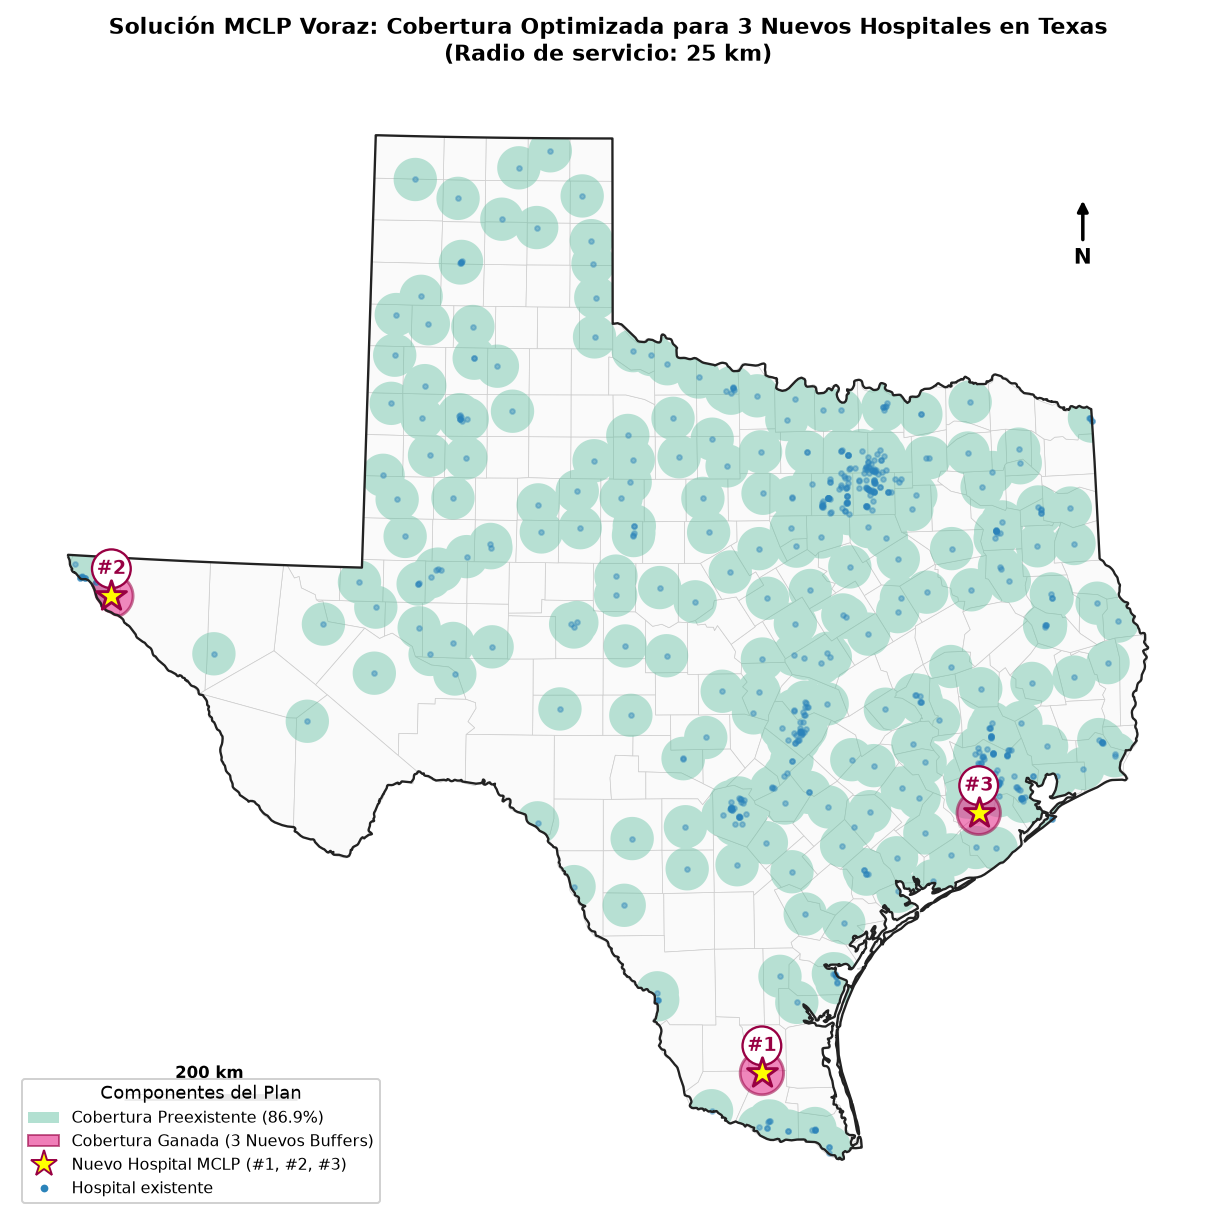

In [15]:
# Mapa de Cobertura Final tras MCLP
fig, ax = plt.subplots(figsize=(11, 9), dpi=140)

# 1. Capa de condados
condados_tx.plot(ax=ax, color="#fafafa", edgecolor="#cccccc", lw=0.35)
estado_gdf.boundary.plot(ax=ax, color="#222222", lw=1.2)

# 2. Cobertura inicial de 25 km
gpd.GeoSeries([cobertura_base], crs=CRS_METRICO).plot(
    ax=ax, color="#66c2a4", alpha=0.45, label="Cobertura inicial 25 km"
)

# 3. Buffers de 25 km de los 3 nuevos hospitales
buffers_nuevos = [candidatos_buffers[idx] for idx in seleccionados]
gpd.GeoSeries(buffers_nuevos, crs=CRS_METRICO).plot(
    ax=ax, color="#e7298a", alpha=0.55, edgecolor="#980043", lw=1.5, label="Nueva cobertura 25 km"
)

# 4. Hospitales existentes
hosp_tx.plot(ax=ax, color="#2b83ba", markersize=6, alpha=0.4, label="Hospitales existentes")

# 5. Puntos seleccionados por el algoritmo voraz
gdf_seleccionados = candidatos_gdf.iloc[seleccionados].copy()
gdf_seleccionados.plot(ax=ax, color="#ffff00", edgecolor="#980043", marker="*", markersize=260, lw=1.5, zorder=6, label="3 Nuevos hospitales (MCLP)")

# Anotación numerada para cada uno de los 3 hospitales seleccionados
for num, (_, row_s) in enumerate(gdf_seleccionados.iterrows(), 1):
    pt = row_s.geometry
    ax.annotate(
        f"#{num}",
        xy=(pt.x, pt.y),
        xytext=(0, 9), textcoords="offset points",
        ha="center", va="bottom",
        fontsize=10, fontweight="bold", color="#980043",
        bbox=dict(boxstyle="circle,pad=0.25", fc="white", ec="#980043", lw=1.2)
    )

decorar_mapa(ax, condados_tx, km=200)

ax.set_title("Solución MCLP Voraz: Cobertura Optimizada para 3 Nuevos Hospitales en Texas\n(Radio de servicio: 25 km)",
             fontsize=11.5, fontweight="bold", pad=12)

# Leyenda personalizada
manejadores = [
    Patch(facecolor="#66c2a4", edgecolor="none", alpha=0.5, label=f"Cobertura Preexistente ({pct_cub_base:.1f}%)"),
    Patch(facecolor="#e7298a", edgecolor="#980043", alpha=0.6, label="Cobertura Ganada (3 Nuevos Buffers)"),
    plt.Line2D([0], [0], marker="*", color="w", markerfacecolor="#ffff00", markeredgecolor="#980043", markersize=14, label="Nuevo Hospital MCLP (#1, #2, #3)"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#2b83ba", markersize=5, label="Hospital existente")
]

ax.legend(handles=manejadores, loc="lower left", fontsize=8, title_fontsize=9, title="Componentes del Plan", framealpha=0.92)
ax.set_axis_off()
plt.tight_layout()
plt.show()


---
## Conclusiones Generales del Task 2

1. **Sensibilidad del Análisis de Buffer y Umbral Crítico:**
   * La curva de cobertura acumulada confirma que un radio de **$25-30\text{ km}$** representa el punto de equilibrio óptimo entre cobertura poblacional ($>86-92\%$) y eficiencia de red en Texas.
   * Superado dicho radio, los rendimientos marginales se desploman por debajo del $2\%$, demostrando que la cobertura del $8\%$ restante en áreas rurales remotas no se resuelve eficientemente con hospitales generales adicionales, sino con redes de transporte urgente, Centros de Acceso Crítico (CAH) y telemedicina.

2. **Doble Penalización Geográfica en Áreas Vulnerables:**
   * El análisis conjunto de distancias y capacidad demostró que los condados más alejados (*Terrell, Jim Hogg, Brewster, Edwards, Hudspeth*) están a más de $69\text{ km}$ de cualquier centro de salud y dependen exclusivamente de instalaciones de muy baja capacidad (de $12$ a $25$ camas).
   * El Índice Compuesto de Vulnerabilidad ($I_v$) sintetiza de manera coherente estas dimensiones, focalizando las áreas prioritarias para intervención de políticas públicas en el oeste y sur del estado.

3. **Eficacia y Límites del Algoritmo Voraz (MCLP):**
   * El algoritmo voraz identificó de manera exitosa los 3 emplazamientos con mayor densidad de población no cubierta bajo un radio de $25\text{ km}$.
   * La solución voraz logra un incremento sustancial en la cobertura poblacional, priorizando conglomerados semirurales desatendidos sobre extensiones despobladas.
